## Modelagem: classificação do aluno alfabetizado

### 0. Imports

In [1]:
import warnings
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb
from joblib import Parallel, delayed
from pathlib import Path
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, balanced_accuracy_score, brier_score_loss, f1_score, log_loss, r2_score, roc_auc_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.validation import has_fit_parameter

### 1. Parâmetros

In [2]:
par_entrada = Path("../data/processed")
par_alvo = "alfabetizado"
par_peso = "peso_amostral"
par_grupo = "nome_mesorregiao"
par_ano_principal = 2024
par_ano_temporal = 2023
par_seed = 42
par_dobras = 5
par_amostra = 50_000
par_amostra_knn = 20_000
par_amostra_temporal = 100_000
par_amostra_interpretacao = 5_000
par_bootstrap = 200
par_jobs = 4
par_faixas_matriculas = [0, 200, 600, 2000, np.inf]
par_rotulos_matriculas = ["<200", "200-599", "600-1999", "2000+"]
par_cores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titlelocation": "left", "axes.titlesize": 11, "font.size": 9})
pd.set_option("display.max_columns", 50, "display.max_rows", 80, "display.float_format", "{:,.3f}".format)

### 2. Funções Auxiliares

In [3]:
def metricas(y, prob, peso):
    return {"auc": roc_auc_score(y, prob, sample_weight=peso), "pr_auc": average_precision_score(y, prob, sample_weight=peso),
            "brier": brier_score_loss(y, prob, sample_weight=peso), "log_loss": log_loss(y, prob, sample_weight=peso)}


def ajustar(modelo, df):
    estimador = modelo.named_steps["modelo"]
    pesos = {"modelo__sample_weight": df[par_peso].values} if has_fit_parameter(estimador, "sample_weight") else {}
    return clone(modelo).fit(df[par_features], df[par_alvo].values, **pesos)


def prever(modelo, df):
    return modelo.predict_proba(df[par_features])[:, 1]


def avaliar_dobra(modelo, df, treino, teste):
    ajustado = ajustar(modelo, df.iloc[treino])
    return (metricas(df[par_alvo].values[treino], prever(ajustado, df.iloc[treino]), df[par_peso].values[treino]),
            metricas(df[par_alvo].values[teste], prever(ajustado, df.iloc[teste]), df[par_peso].values[teste]))


def validacao_cruzada(modelo, df=None, n_jobs=par_jobs):
    df = df_amostra if df is None else df
    dobras = par_cv.split(df, groups=df[par_grupo])
    return Parallel(n_jobs=n_jobs)(delayed(avaliar_dobra)(modelo, df, tr, te) for tr, te in dobras)


def validar(nome, modelo, df=None):
    df = df_amostra if df is None else df
    dobras = validacao_cruzada(modelo, df)
    ajustado = ajustar(modelo, df)
    return {"modelo": nome, "auc_treino": np.mean([t["auc"] for t, _ in dobras]), "auc_cv": np.mean([v["auc"] for _, v in dobras]), "dp_cv": np.std([v["auc"] for _, v in dobras]),
            "pr_auc_cv": np.mean([v["pr_auc"] for _, v in dobras]), "brier_cv": np.mean([v["brier"] for _, v in dobras]),
            **{f"{k}_validacao": v for k, v in metricas(df_validacao[par_alvo].values, prever(ajustado, df_validacao), df_validacao[par_peso].values).items()}}


def avaliar_parametros(modelo, parametros):
    dobras = validacao_cruzada(clone(modelo).set_params(**parametros), n_jobs=1)
    return np.mean([v["auc"] for _, v in dobras])


def buscar(estimador, grade):
    pipe = Pipeline([("prep", clone(preprocessador)), ("modelo", estimador)])
    candidatos = list(ParameterGrid(grade))
    notas = Parallel(n_jobs=par_jobs)(delayed(avaliar_parametros)(pipe, p) for p in candidatos)
    melhor = candidatos[int(np.argmax(notas))]
    return pipe.set_params(**melhor), melhor


def sem_colunas(prep, remover, sem_indicadores=False):
    novo = clone(prep)
    novo.transformers = [(n, t, [c for c in cols if c not in remover]) for n, t, cols in novo.transformers
                         if not (sem_indicadores and n == "ausente")]
    return novo


def bootstrap_grupos(grupos, funcao, repeticoes=par_bootstrap, seed=par_seed):
    rng = np.random.default_rng(seed)
    posicoes = pd.Series(np.arange(len(grupos))).groupby(np.asarray(grupos)).apply(lambda s: s.values)
    valores = []
    for _ in range(repeticoes):
        indices = np.concatenate(posicoes.values[rng.integers(0, len(posicoes), len(posicoes))])
        valores.append(funcao(indices))
    return np.percentile(valores, [2.5, 50, 97.5])


def plot_barras(df, x, y, hue=None, titulo="", xlabel=None, referencia=None, fmt="%.3f", figsize=None, xlim=None):
    ordem = df[x].drop_duplicates().tolist()
    tab = df.pivot(index=x, columns=hue, values=y).reindex(ordem) if hue else df.set_index(x)[[y]]
    altura = max(2.4, .3 * len(tab) * (tab.shape[1] if hue else 1) + 1)
    ax = tab[::-1].plot.barh(figsize=figsize or (8, altura), color=par_cores[:tab.shape[1]], width=.8, edgecolor="white", linewidth=1.5, legend=bool(hue))
    if referencia is not None:
        ax.axvline(referencia, color="#52514e", linestyle="--", linewidth=1)
    if not hue:
        ax.bar_label(ax.containers[0], fmt=fmt, padding=3, fontsize=8)
    ax.grid(axis="y", visible=False)
    ax.set(title=titulo, xlabel=xlabel or y, ylabel="")
    if xlim:
        ax.set_xlim(*xlim)
    plt.tight_layout()
    plt.show()

### 3. Leitura de dados

In [4]:
df_catalogo = pd.read_csv(par_entrada / "catalogo_features.csv")
preprocessador = joblib.load(par_entrada / "preprocessador_aluno.joblib")
par_features = df_catalogo.loc[df_catalogo["modelo_aluno"], "feature"].tolist()
par_familias = df_catalogo[df_catalogo["modelo_aluno"]].groupby("familia")["feature"].apply(list).to_dict()
df_aluno = pd.read_parquet(par_entrada / "base_aluno.parquet")
par_inteiras = df_aluno.select_dtypes("Int64").columns.drop("ano_alvo")
df_aluno[par_inteiras] = df_aluno[par_inteiras].astype("float32")
df_aluno["faixa_matriculas"] = pd.cut(df_aluno["matriculas_anos_iniciais"], par_faixas_matriculas, labels=par_rotulos_matriculas, right=False)
df_2023 = df_aluno[df_aluno["ano_alvo"] == par_ano_temporal].copy()
df_2024 = df_aluno[df_aluno["ano_alvo"] == par_ano_principal].copy()
del df_aluno
df_2024.groupby("split").agg(alunos=(par_alvo, "size"), escolas=("id_escola", "nunique"), municipios=("id_municipio", "nunique"), mesorregioes=(par_grupo, "nunique"), ufs=("sigla_uf", "nunique"),
                             pct_alfabetizado=(par_alvo, lambda s: 100 * s.mean()))

,alunos,escolas,municipios,mesorregioes,ufs,pct_alfabetizado
split,,,,,,
teste,276972,8460,1204,33,16,63.135
treino,1296903,26713,2877,68,26,58.972
validacao,277953,7154,1436,34,19,60.237


In [5]:
print("Combinações de município e rede:", df_2024.drop_duplicates(["id_municipio", "rede_id"]).shape[0], "| Escolas:", df_2024["id_escola"].nunique(), "| Alunos:", len(df_2024))
print("Features que variam dentro de município e rede:", [c for c in par_features if df_2024.sample(200_000, random_state=par_seed).groupby(["id_municipio", "rede_id"])[c].nunique().max() > 1])

Combinações de município e rede: 6535 | Escolas: 42327 | Alunos: 1851828


Features que variam dentro de município e rede: ['alunos_previstos_escola']


### 4. Partições e validação

In [6]:
df_treino = df_2024[df_2024["split"] == "treino"]
df_validacao = df_2024[df_2024["split"] == "validacao"]
df_teste = df_2024[df_2024["split"] == "teste"]
df_amostra = df_treino.sample(par_amostra, random_state=par_seed)
df_amostra_knn = df_amostra.sample(par_amostra_knn, random_state=par_seed)
par_cv = GroupKFold(n_splits=par_dobras)
assert not set(df_treino[par_grupo]) & set(df_validacao[par_grupo]) | set(df_treino[par_grupo]) & set(df_teste[par_grupo]) | set(df_validacao[par_grupo]) & set(df_teste[par_grupo])
assert not set(par_features) & {par_alvo, par_peso, "split", "id_escola", "id_municipio", par_grupo, "ano_alvo"}
print("Amostra:", df_amostra.shape, "| Treino:", df_treino.shape, "| Validação:", df_validacao.shape, "| Teste:", df_teste.shape)
resultados = {}
modelos = {}

Amostra: (50000, 47) | Treino: (1296903, 47) | Validação: (277953, 47) | Teste: (276972, 47)


**Decisão:** validar por mesorregião, com `GroupKFold` e sem repetir mesorregião entre treino, validação e teste. Quase todas as features descrevem o município e a rede (só `alunos_previstos_escola` varia dentro dessa combinação), então separar por aluno colocaria o mesmo contexto nos dois lados e inflaria o resultado.

A comparação de modelos usa uma amostra de 50 mil alunos, e o KNN usa 20 mil porque seu consumo de memória cresce com o número de linhas previstas e de vizinhos. O ajuste final usa a base completa.

### 5. Referências simples

#### Proporção do treino

In [7]:
modelos["Proporção"] = Pipeline([("prep", clone(preprocessador)), ("modelo", DummyClassifier(strategy="prior"))])
resultados["Proporção"] = validar("Proporção", modelos["Proporção"])
resultados["Proporção"]

{'modelo': 'Proporção',
 'auc_treino': np.float64(0.5),
 'auc_cv': np.float64(0.5),
 'dp_cv': np.float64(0.0),
 'pr_auc_cv': np.float64(0.5840012867538548),
 'brier_cv': np.float64(0.24361320420689503),
 'auc_validacao': 0.5,
 'pr_auc_validacao': 0.5991377157841788,
 'brier_validacao': 0.24039601999868965,
 'log_loss_validacao': 0.6738231161299679}

#### Persistência: taxa do município em 2023

In [8]:
def prob_persistencia(df, mediana):
    return df["taxa_lag"].fillna(mediana).astype(float).values / 100


linhas = []
for treino, teste in par_cv.split(df_amostra, groups=df_amostra[par_grupo]):
    mediana = df_amostra.iloc[treino]["taxa_lag"].median()
    linhas.append(metricas(df_amostra[par_alvo].values[teste], prob_persistencia(df_amostra.iloc[teste], mediana), df_amostra[par_peso].values[teste]))
mediana_lag = df_amostra["taxa_lag"].median()
resultados["Persistência"] = {"modelo": "Persistência", "auc_treino": metricas(df_amostra[par_alvo].values, prob_persistencia(df_amostra, mediana_lag), df_amostra[par_peso].values)["auc"],
                              "auc_cv": np.mean([l["auc"] for l in linhas]), "dp_cv": np.std([l["auc"] for l in linhas]), "pr_auc_cv": np.mean([l["pr_auc"] for l in linhas]), "brier_cv": np.mean([l["brier"] for l in linhas]),
                              **{f"{k}_validacao": v for k, v in metricas(df_validacao[par_alvo].values, prob_persistencia(df_validacao, mediana_lag), df_validacao[par_peso].values).items()}}
resultados["Persistência"]

{'modelo': 'Persistência',
 'auc_treino': 0.6191958142944101,
 'auc_cv': np.float64(0.6152640293141304),
 'dp_cv': np.float64(0.02467812180368854),
 'pr_auc_cv': np.float64(0.675927655847996),
 'brier_cv': np.float64(0.23441458392431383),
 'auc_validacao': 0.6411640349233667,
 'pr_auc_validacao': 0.7167687098191218,
 'brier_validacao': 0.22789037838336448,
 'log_loss_validacao': 0.6640152161082288}

### 6. Benchmark: KNN

In [9]:
modelos["KNN"] = Pipeline([("prep", clone(preprocessador)), ("modelo", KNeighborsClassifier(n_neighbors=200))])
resultados["KNN"] = validar("KNN", modelos["KNN"], df_amostra_knn)
resultados["KNN"]

{'modelo': 'KNN',
 'auc_treino': np.float64(0.649522901640535),
 'auc_cv': np.float64(0.621879015868926),
 'dp_cv': np.float64(0.018567369127429907),
 'pr_auc_cv': np.float64(0.6810192175251586),
 'brier_cv': np.float64(0.2332051333444655),
 'auc_validacao': 0.6483315168439473,
 'pr_auc_validacao': 0.722292246646027,
 'brier_validacao': 0.22441485993585564,
 'log_loss_validacao': 0.6396264708575894}

### 7. Modelos lineares

#### Regressão logística

In [10]:
modelos["Logística"] = Pipeline([("prep", clone(preprocessador)), ("modelo", LogisticRegression(C=1e6, max_iter=3000))])
resultados["Logística"] = validar("Logística", modelos["Logística"])
resultados["Logística"]

{'modelo': 'Logística',
 'auc_treino': np.float64(0.6497498183666612),
 'auc_cv': np.float64(0.6340206343559728),
 'dp_cv': np.float64(0.013419451909629133),
 'pr_auc_cv': np.float64(0.6943262993546494),
 'brier_cv': np.float64(0.22925367124482995),
 'auc_validacao': 0.6608857015751408,
 'pr_auc_validacao': 0.7386017003879286,
 'brier_validacao': 0.22181485524024266,
 'log_loss_validacao': 0.6334276996081944}

#### Logística L2

In [11]:
modelos["Logística L2"], par_l2 = buscar(LogisticRegression(max_iter=3000), {"modelo__C": [.01, .1, 1]})
resultados["Logística L2"] = validar("Logística L2", modelos["Logística L2"])
print(par_l2)
resultados["Logística L2"]

{'modelo__C': 0.01}


{'modelo': 'Logística L2',
 'auc_treino': np.float64(0.6489546012602325),
 'auc_cv': np.float64(0.6370486249352422),
 'dp_cv': np.float64(0.014528390465588615),
 'pr_auc_cv': np.float64(0.6972376251996056),
 'brier_cv': np.float64(0.22829311180020068),
 'auc_validacao': 0.6607274922280209,
 'pr_auc_validacao': 0.738137469383996,
 'brier_validacao': 0.2217529978444994,
 'log_loss_validacao': 0.6333268940743946}

#### Logística L1

In [12]:
modelos["Logística L1"], par_l1 = buscar(LogisticRegression(l1_ratio=1, solver="saga", max_iter=500, tol=1e-3), {"modelo__C": [.01, .1]})
resultados["Logística L1"] = validar("Logística L1", modelos["Logística L1"])
print(par_l1)
resultados["Logística L1"]

{'modelo__C': 0.1}


{'modelo': 'Logística L1',
 'auc_treino': np.float64(0.6490399549235116),
 'auc_cv': np.float64(0.6380997396025099),
 'dp_cv': np.float64(0.014440857743283726),
 'pr_auc_cv': np.float64(0.6979834782679072),
 'brier_cv': np.float64(0.2280590569508189),
 'auc_validacao': 0.6610095280844812,
 'pr_auc_validacao': 0.7387110310161397,
 'brier_validacao': 0.22172003448305588,
 'log_loss_validacao': 0.6332191415937536}

### 8. Árvores

#### Árvore de decisão

In [13]:
modelos["Árvore"], par_arvore = buscar(DecisionTreeClassifier(random_state=par_seed), {"modelo__max_depth": [4, 6, 8], "modelo__min_samples_leaf": [200, 1000]})
resultados["Árvore"] = validar("Árvore", modelos["Árvore"])
print(par_arvore)
resultados["Árvore"]

{'modelo__max_depth': 4, 'modelo__min_samples_leaf': 200}


{'modelo': 'Árvore',
 'auc_treino': np.float64(0.6397152977341397),
 'auc_cv': np.float64(0.6197661601522672),
 'dp_cv': np.float64(0.023006083018128832),
 'pr_auc_cv': np.float64(0.6667337636005886),
 'brier_cv': np.float64(0.23282016855798976),
 'auc_validacao': 0.6365263406345262,
 'pr_auc_validacao': 0.6915633371390866,
 'brier_validacao': 0.22594037069733006,
 'log_loss_validacao': 0.6431592743139543}

#### Random Forest

In [14]:
modelos["Random Forest"], par_rf = buscar(RandomForestClassifier(n_estimators=50, max_features=.3, random_state=par_seed, n_jobs=1),
                                          {"modelo__max_depth": [6, 10], "modelo__min_samples_leaf": [100, 500]})
resultados["Random Forest"] = validar("Random Forest", modelos["Random Forest"])
print(par_rf)
resultados["Random Forest"]

{'modelo__max_depth': 10, 'modelo__min_samples_leaf': 100}


{'modelo': 'Random Forest',
 'auc_treino': np.float64(0.6739052052704194),
 'auc_cv': np.float64(0.6315842337000009),
 'dp_cv': np.float64(0.020373648754101182),
 'pr_auc_cv': np.float64(0.6923100472107533),
 'brier_cv': np.float64(0.22927874899213124),
 'auc_validacao': 0.6615384680738352,
 'pr_auc_validacao': 0.7401716320553952,
 'brier_validacao': 0.22175169092669175,
 'log_loss_validacao': 0.6332918383066058}

### 9. Boosting

#### XGBoost

In [15]:
modelos["XGBoost"], par_xgb = buscar(xgb.XGBClassifier(n_estimators=200, learning_rate=.05, subsample=.8, colsample_bytree=.6, random_state=par_seed, n_jobs=1, tree_method="hist"),
                                     {"modelo__max_depth": [3, 5], "modelo__min_child_weight": [50, 500]})
resultados["XGBoost"] = validar("XGBoost", modelos["XGBoost"])
print(par_xgb)
resultados["XGBoost"]

{'modelo__max_depth': 3, 'modelo__min_child_weight': 50}


{'modelo': 'XGBoost',
 'auc_treino': np.float64(0.6644470201395781),
 'auc_cv': np.float64(0.6327013102310354),
 'dp_cv': np.float64(0.01885252892787475),
 'pr_auc_cv': np.float64(0.6938856507966167),
 'brier_cv': np.float64(0.22929105758666993),
 'auc_validacao': 0.6620029552241882,
 'pr_auc_validacao': 0.7388804181391646,
 'brier_validacao': 0.22175803780555725,
 'log_loss_validacao': 0.6334142088890076}

#### LightGBM

In [16]:
modelos["LightGBM"], par_lgb = buscar(lgb.LGBMClassifier(n_estimators=200, learning_rate=.05, subsample=.8, subsample_freq=1, colsample_bytree=.6, random_state=par_seed, n_jobs=1, verbose=-1),
                                      {"modelo__num_leaves": [7, 15], "modelo__min_child_samples": [200, 1000]})
resultados["LightGBM"] = validar("LightGBM", modelos["LightGBM"])
print(par_lgb)
resultados["LightGBM"]

{'modelo__min_child_samples': 1000, 'modelo__num_leaves': 7}


{'modelo': 'LightGBM',
 'auc_treino': np.float64(0.6632388592262682),
 'auc_cv': np.float64(0.634020459429275),
 'dp_cv': np.float64(0.01731481248157479),
 'pr_auc_cv': np.float64(0.6945191185692641),
 'brier_cv': np.float64(0.22907888727636205),
 'auc_validacao': 0.6636428513021042,
 'pr_auc_validacao': 0.7395512748389632,
 'brier_validacao': 0.22141636912655463,
 'log_loss_validacao': 0.6327029127975566}

### 10. Comparação

In [17]:
df_resultados = pd.DataFrame(resultados.values()).sort_values("auc_cv", ascending=False).reset_index(drop=True)
auc_knn = df_resultados.loc[df_resultados["modelo"] == "KNN", "auc_cv"].item()
df_resultados["ganho_auc_vs_knn"] = df_resultados["auc_cv"] - auc_knn
df_resultados["sobreajuste"] = df_resultados["auc_treino"] - df_resultados["auc_cv"]
df_resultados

,modelo,auc_treino,auc_cv,dp_cv,pr_auc_cv,brier_cv,auc_validacao,pr_auc_validacao,brier_validacao,log_loss_validacao,ganho_auc_vs_knn,sobreajuste
0,Logística L1,0.649,0.638,0.014,0.698,0.228,0.661,0.739,0.222,0.633,0.016,0.011
1,Logística L2,0.649,0.637,0.015,0.697,0.228,0.661,0.738,0.222,0.633,0.015,0.012
2,Logística,0.650,0.634,0.013,0.694,0.229,0.661,0.739,0.222,0.633,0.012,0.016
3,LightGBM,0.663,0.634,0.017,0.695,0.229,0.664,0.740,0.221,0.633,0.012,0.029
4,XGBoost,0.664,0.633,0.019,0.694,0.229,0.662,0.739,0.222,0.633,0.011,0.032
5,Random Forest,0.674,0.632,0.020,0.692,0.229,0.662,0.740,0.222,0.633,0.010,0.042
6,KNN,0.650,0.622,0.019,0.681,0.233,0.648,0.722,0.224,0.640,0.000,0.028
7,Árvore,0.640,0.620,0.023,0.667,0.233,0.637,0.692,0.226,0.643,-0.002,0.020
8,Persistência,0.619,0.615,0.025,0.676,0.234,0.641,0.717,0.228,0.664,-0.007,0.004
9,Proporção,0.500,0.500,0.000,0.584,0.244,0.500,0.599,0.240,0.674,-0.122,0.000


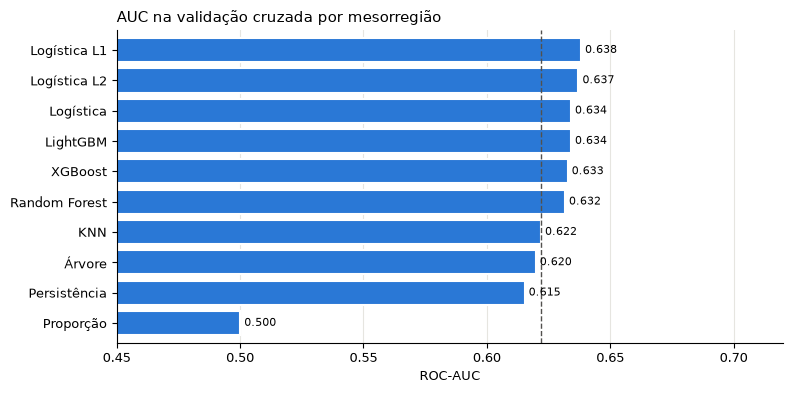

In [18]:
plot_barras(df_resultados, "modelo", "auc_cv", titulo="AUC na validação cruzada por mesorregião", xlabel="ROC-AUC", referencia=auc_knn, xlim=(.45, .72))

In [19]:
par_melhor = "LightGBM"
print("Melhor modelo na validação cruzada:", df_resultados[~df_resultados["modelo"].isin(["Proporção", "Persistência"])].iloc[0]["modelo"])
print("Modelo adotado:", par_melhor)
print("Melhor modelo na partição de validação:", df_resultados.sort_values("auc_validacao", ascending=False).iloc[0]["modelo"])

Melhor modelo na validação cruzada: Logística L1
Modelo adotado: LightGBM
Melhor modelo na partição de validação: LightGBM


**Decisão:** seguir com o LightGBM (`num_leaves=7`, `min_child_samples=1000`).

- **Contra as referências:** o AUC na validação cruzada foi de 0,634, contra 0,622 do KNN e 0,615 da persistência. Na partição de validação, foi de 0,664, contra 0,648 e 0,641.
- **Contra as logísticas:** a Logística L1 teve AUC maior na validação cruzada (0,638) e menor na partição de validação (0,661). A diferença de 0,004 na validação cruzada é menor que a variação entre dobras (cerca de 0,015), então os dois modelos estão tecnicamente empatados. O LightGBM foi mantido por ir melhor na partição de validação e, como mostra a seção 12, no teste temporal (0,708 contra 0,697 da Logística L2).
- **Complexidade:** a busca escolheu a menor profundidade ou o menor número de folhas na árvore, no XGBoost e no LightGBM, e o menor `C` na Logística L2. Isso indica pouco sinal além de relações simples, e o sobreajuste aumenta com a flexibilidade do modelo (0,011 na Logística L1, 0,029 no LightGBM e 0,042 na Random Forest).

### 11. Testes de variáveis

In [20]:
par_ablacao = {"Todas as features": ([], False),
               **{f"Sem {fam}": (cols, False) for fam, cols in par_familias.items()},
               "Sem UF": (["sigla_uf"], False),
               "Sem território": (par_familias["territorio_categorico"] + par_familias["territorio_numerico"], False),
               "Sem indicadores de ausência": ([], True),
               "Sem presença e nº de avaliados": (["taxa_presenca_lag", "n_avaliados_lag"], False)}
linhas = []
for nome, (remover, sem_indicadores) in par_ablacao.items():
    pipe = clone(modelos[par_melhor]).set_params(prep=sem_colunas(preprocessador, remover, sem_indicadores))
    linhas.append({"cenario": nome, "auc_cv": np.mean([v["auc"] for _, v in validacao_cruzada(pipe)])})
df_ablacao = pd.DataFrame(linhas)
df_ablacao["diferenca"] = df_ablacao["auc_cv"] - df_ablacao.loc[0, "auc_cv"]
df_ablacao.sort_values("auc_cv", ascending=False)

,cenario,auc_cv,diferenca
7,Sem rede,0.634,0.000
0,Todas as features,0.634,0.000
6,Sem infraestrutura,0.634,-0.000
1,Sem docentes_turmas,0.634,-0.001
8,Sem socioeconomico,0.633,-0.001
14,Sem presença e nº de avaliados,0.633,-0.001
13,Sem indicadores de ausência,0.633,-0.001
3,Sem financiamento,0.633,-0.001
4,Sem fluxo_escolar,0.633,-0.001
10,Sem territorio_numerico,0.633,-0.001


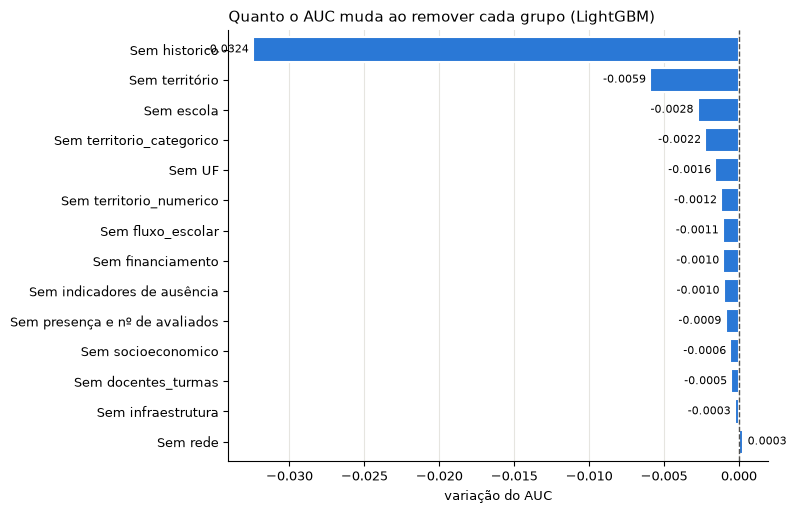

In [21]:
plot_barras(df_ablacao[df_ablacao["cenario"] != "Todas as features"].sort_values("diferenca"), "cenario", "diferenca",
            titulo=f"Quanto o AUC muda ao remover cada grupo ({par_melhor})", xlabel="variação do AUC", referencia=0, fmt="%.4f")

### 12. Generalização mais exigente

#### Por UF: alunos de um estado nunca visto

In [22]:
df_uf = pd.concat([df_amostra, df_validacao.sample(par_amostra // 4, random_state=par_seed)])
linhas = []
for nome in dict.fromkeys(["KNN", "Logística L2", par_melhor]):
    base = df_uf.sample(par_amostra_knn, random_state=par_seed) if nome == "KNN" else df_uf
    dobras = par_cv.split(base, groups=base["sigla_uf"])
    notas = Parallel(n_jobs=par_jobs)(delayed(avaliar_dobra)(modelos[nome], base, tr, te) for tr, te in dobras)
    linhas.append({"modelo": nome, "auc": np.mean([v["auc"] for _, v in notas]), "dp": np.std([v["auc"] for _, v in notas])})
linhas.append({"modelo": "Persistência", "auc": roc_auc_score(df_uf[par_alvo], prob_persistencia(df_uf, mediana_lag), sample_weight=df_uf[par_peso]), "dp": np.nan})
pd.DataFrame(linhas).sort_values("auc", ascending=False)

,modelo,auc,dp
2,LightGBM,0.629,0.031
1,Logística L2,0.628,0.027
3,Persistência,0.622,NaN
0,KNN,0.605,0.040


#### Temporal: treinar com alunos de 2023 e testar em 2024

In [23]:
par_sem_tempo = par_familias["historico"]
df_amostra_2023 = df_2023.sample(min(par_amostra_temporal, len(df_2023)), random_state=par_seed)
linhas = []
for nome in dict.fromkeys(["KNN", "Logística L2", par_melhor]):
    pipe = clone(modelos[nome]).set_params(prep=sem_colunas(preprocessador, par_sem_tempo, True))
    base = df_amostra_2023.sample(par_amostra_knn, random_state=par_seed) if nome == "KNN" else df_amostra_2023
    ajustado = ajustar(pipe, base)
    linhas.append({"modelo": nome, **metricas(df_teste[par_alvo].values, prever(ajustado, df_teste), df_teste[par_peso].values)})
print("Alunos em 2023:", len(df_2023), "| UFs:", df_2023["sigla_uf"].nunique(), "| Teste: mesorregiões de teste de 2024")
pd.DataFrame(linhas).sort_values("auc", ascending=False)

Alunos em 2023: 1502809 | UFs: 23 | Teste: mesorregiões de teste de 2024


,modelo,auc,pr_auc,brier,log_loss
2,LightGBM,0.708,0.805,0.206,0.594
1,Logística L2,0.697,0.793,0.209,0.604
0,KNN,0.685,0.783,0.212,0.610


### 13. Avaliação final no teste

In [24]:
par_finalistas = list(dict.fromkeys(["Logística L2", par_melhor]))
df_ajuste = pd.concat([df_treino, df_validacao])
finais = {n: ajustar(modelos[n], df_ajuste) for n in par_finalistas}
finais["KNN"] = ajustar(modelos["KNN"], df_amostra_knn)
y_teste, peso_teste = df_teste[par_alvo].values, df_teste[par_peso].values
previsoes_teste = {n: prever(m, df_teste) for n, m in finais.items()}
previsoes_teste["Persistência"] = prob_persistencia(df_teste, df_ajuste["taxa_lag"].median())
previsoes_teste["Proporção"] = np.full(len(df_teste), np.average(df_ajuste[par_alvo], weights=df_ajuste[par_peso]))
df_teste_final = pd.DataFrame([{"modelo": n, **metricas(y_teste, p, peso_teste)} for n, p in previsoes_teste.items()]).sort_values("auc", ascending=False)
df_teste_final

,modelo,auc,pr_auc,brier,log_loss
1,LightGBM,0.730,0.822,0.200,0.580
0,Logística L2,0.730,0.823,0.200,0.581
2,KNN,0.719,0.810,0.205,0.594
3,Persistência,0.714,0.810,0.206,0.605
4,Proporção,0.500,0.623,0.236,0.665


**O ganho é real? Intervalo de 95% por bootstrap de mesorregiões**

In [25]:
def ganho(referencia):
    return bootstrap_grupos(df_teste[par_grupo].values, lambda i: roc_auc_score(y_teste[i], previsoes_teste[par_melhor][i], sample_weight=peso_teste[i]) - roc_auc_score(y_teste[i], previsoes_teste[referencia][i], sample_weight=peso_teste[i]))


auc_ic = bootstrap_grupos(df_teste[par_grupo].values, lambda i: roc_auc_score(y_teste[i], previsoes_teste[par_melhor][i], sample_weight=peso_teste[i]))
pd.DataFrame([auc_ic, ganho("KNN"), ganho("Persistência")], columns=["p2.5", "mediana", "p97.5"], index=[f"AUC de {par_melhor}", "Melhor - KNN", "Melhor - Persistência"])

,p2.5,mediana,p97.5
AUC de LightGBM,0.677,0.728,0.778
Melhor - KNN,0.007,0.011,0.019
Melhor - Persistência,0.006,0.016,0.028


**Teto do contexto: quanto seria possível acertar conhecendo a taxa real do grupo**

In [26]:
linhas = [{"referencia": f"{par_melhor} (modelo)", "auc": roc_auc_score(y_teste, previsoes_teste[par_melhor], sample_weight=peso_teste)}]
for nome, grupo in {"Taxa real de 2024 do município e rede": ["id_municipio", "rede_id"], "Taxa real de 2024 da escola": ["id_escola"]}.items():
    taxa = df_teste.groupby(grupo)[par_alvo].transform("mean").values
    linhas.append({"referencia": nome, "auc": roc_auc_score(y_teste, taxa, sample_weight=peso_teste)})
df_teto = pd.DataFrame(linhas)
df_teto

,referencia,auc
0,LightGBM (modelo),0.730
1,Taxa real de 2024 do município e rede,0.751
2,Taxa real de 2024 da escola,0.798


**Limiar de decisão, definido na validação**

In [27]:
prob_validacao = prever(ajustar(modelos[par_melhor], df_amostra), df_validacao)
par_limiares = np.arange(.3, .8, .01)
par_limiar = par_limiares[np.argmax([balanced_accuracy_score(df_validacao[par_alvo], prob_validacao >= l, sample_weight=df_validacao[par_peso]) for l in par_limiares])]
linhas = []
for nome, limiar in {"0,50": .5, f"{par_limiar:.2f} (validação)": par_limiar}.items():
    classe = previsoes_teste[par_melhor] >= limiar
    linhas.append({"limiar": nome, "acuracia_balanceada": balanced_accuracy_score(y_teste, classe, sample_weight=peso_teste), "f1_alfabetizado": f1_score(y_teste, classe, sample_weight=peso_teste),
                   "f1_nao_alfabetizado": f1_score(y_teste, classe, pos_label=0, sample_weight=peso_teste), "pct_previsto_alfabetizado": 100 * np.average(classe, weights=peso_teste)})
pd.DataFrame(linhas)

,limiar,acuracia_balanceada,f1_alfabetizado,f1_nao_alfabetizado,pct_previsto_alfabetizado
0,"0,50",0.640,0.760,0.527,70.325
1,0.63 (validação),0.669,0.678,0.617,46.409


**Calibração**

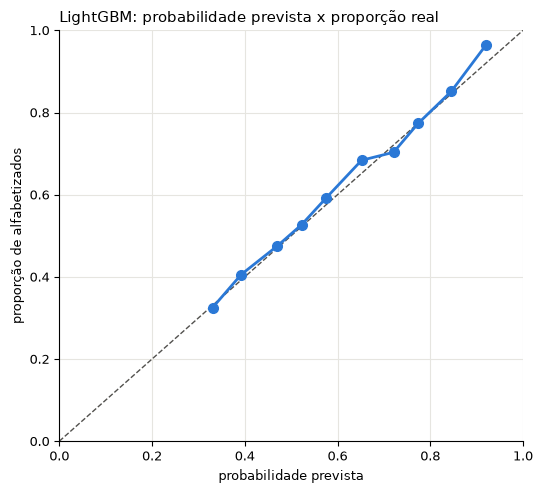

,previsto,observado,alunos
faixa,,,
"(0.279, 0.367]",0.331,0.325,"27,799.000"
"(0.367, 0.429]",0.392,0.406,"27,672.000"
"(0.429, 0.503]",0.470,0.475,"27,729.000"
"(0.503, 0.539]",0.523,0.527,"27,680.000"
"(0.539, 0.611]",0.576,0.593,"27,629.000"
"(0.611, 0.692]",0.652,0.684,"27,710.000"
"(0.692, 0.749]",0.721,0.703,"27,790.000"
"(0.749, 0.8]",0.774,0.773,"27,572.000"
"(0.8, 0.898]",0.845,0.851,"27,746.000"


In [28]:
df_calibracao = pd.DataFrame({"prob": previsoes_teste[par_melhor], "real": y_teste, "peso": peso_teste})
df_calibracao["faixa"] = pd.qcut(df_calibracao["prob"], 10, duplicates="drop")
df_curva = df_calibracao.groupby("faixa", observed=True).apply(lambda d: pd.Series({"previsto": np.average(d["prob"], weights=d["peso"]), "observado": np.average(d["real"], weights=d["peso"]), "alunos": len(d)}))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color="#52514e", linestyle="--", linewidth=1)
ax.plot(df_curva["previsto"], df_curva["observado"], marker="o", markersize=7, linewidth=2, color=par_cores[0])
ax.set(title=f"{par_melhor}: probabilidade prevista x proporção real", xlabel="probabilidade prevista", ylabel="proporção de alfabetizados", xlim=(0, 1), ylim=(0, 1))
plt.tight_layout()
plt.show()
df_curva

**Desempenho por segmento**

In [29]:
def por_segmento(coluna):
    linhas = []
    for grupo, d in df_erro.groupby(coluna, observed=True):
        if d[par_alvo].nunique() == 2 and len(d) >= 1000:
            linhas.append({"segmento": coluna, "grupo": grupo, "alunos": len(d), "auc": roc_auc_score(d[par_alvo], d["prob"], sample_weight=d[par_peso]),
                           "real_pct": 100 * np.average(d[par_alvo], weights=d[par_peso]), "previsto_pct": 100 * np.average(d["prob"], weights=d[par_peso])})
    return linhas


df_erro = df_teste.assign(prob=previsoes_teste[par_melhor])
df_segmentos = pd.DataFrame([l for c in ["nome_regiao", "rede", "faixa_matriculas", "sigla_uf"] for l in por_segmento(c)])
df_segmentos["vies"] = df_segmentos["previsto_pct"] - df_segmentos["real_pct"]
df_segmentos.set_index(["segmento", "grupo"])

alunos   auc  real_pct  previsto_pct   vies
segmento         grupo                                                    
nome_regiao      Centro-Oeste    3459 0.538    43.746        50.309  6.564
                 Nordeste      114474 0.815    66.850        66.066 -0.784
                 Norte          50751 0.591    46.121        44.661 -1.460
                 Sudeste        47221 0.602    70.543        70.975  0.432
                 Sul            61067 0.640    63.451        61.236 -2.216
rede             Estadual       25460 0.641    64.007        62.479 -1.528
                 Municipal     251512 0.738    62.152        61.244 -0.908
faixa_matriculas <200            4347 0.659    68.317        67.726 -0.591
                 200-599        27745 0.668    68.196        68.334  0.138
                 600-1999       88347 0.729    66.616        64.905 -1.711
                 2000+         156533 0.729    58.825        58.059 -0.767
sigla_uf         AC              2791 0.546    50.560        51.598  1.037
                 AL              5048 0.653    47.982        49.143  1.161
                 AM              6158 0.627    44.748        46.641  1.893
                 BA             21011 0.543    30.798        34.071  3.273
                 CE             51336 0.757    89.619        87.616 -2.002
                 MA             27910 0.619    60.586        58.574 -2.012
                 MG             37661 0.603    71.109        71.877  0.768
                 MS              3459 0.538    43.746        50.309  6.564
                 PA             41802 0.586    46.011        43.906 -2.106
                 PI              5557 0.681    61.867        62.307  0.440
                 PR             19223 0.589    74.777        75.655  0.878
                 RJ              2375 0.552    66.879        65.071 -1.809
                 RS             12734 0.583    47.247        46.790 -0.457
                 SC             29110 0.588    63.611        59.072 -4.539
                 SE              3612 0.538    38.735        37.489 -1.246
                 SP              7185 0.589    68.751        68.141 -0.610

**Da previsão por aluno à taxa do município**

Municípios comparados: 1135 | RMSE: 11.23 | R²: 0.712


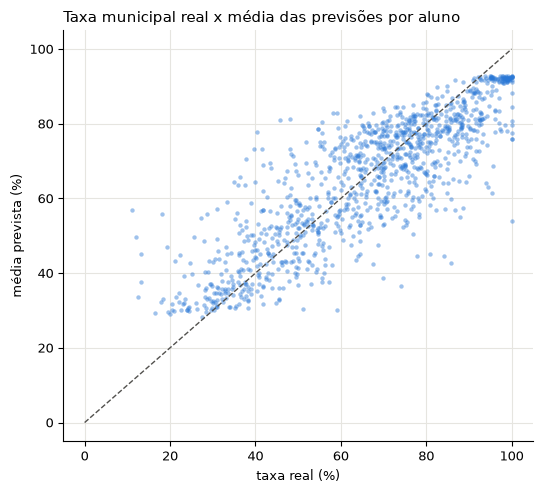

In [30]:
df_municipio = pd.read_parquet(par_entrada / "base_municipio.parquet", columns=["id_municipio", "taxa_alfabetizacao", "split"])
df_agregado = (df_erro[df_erro["rede_id"] == "3"].groupby("id_municipio").apply(lambda d: 100 * np.average(d["prob"], weights=d[par_peso])).rename("taxa_agregada").reset_index()
               .merge(df_municipio[df_municipio["split"] == "teste"], on="id_municipio"))
print("Municípios comparados:", len(df_agregado), "| RMSE:", round(root_mean_squared_error(df_agregado["taxa_alfabetizacao"], df_agregado["taxa_agregada"]), 2), "| R²:", round(r2_score(df_agregado["taxa_alfabetizacao"], df_agregado["taxa_agregada"]), 3))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(df_agregado["taxa_alfabetizacao"], df_agregado["taxa_agregada"], s=10, alpha=.45, color=par_cores[0], linewidths=0)
ax.plot([0, 100], [0, 100], color="#52514e", linestyle="--", linewidth=1)
ax.set(title="Taxa municipal real x média das previsões por aluno", xlabel="taxa real (%)", ylabel="média prevista (%)")
plt.tight_layout()
plt.show()

### 14. Interpretabilidade

#### Importância por permutação (teste)

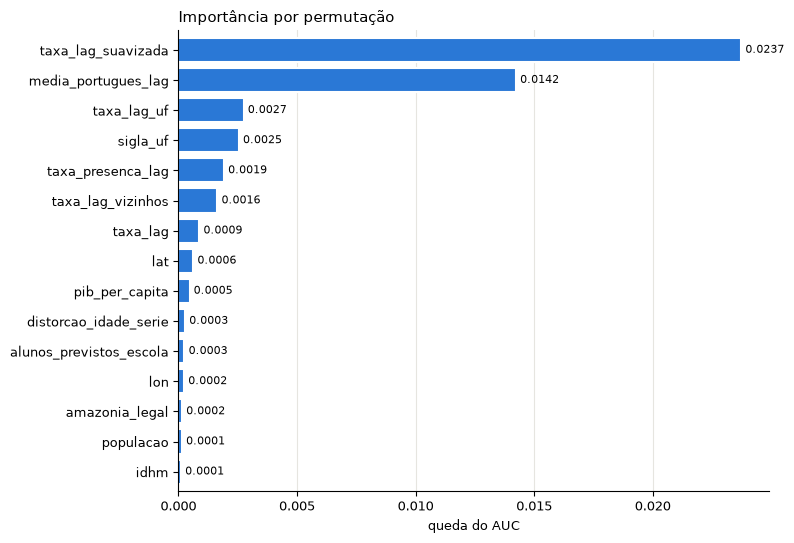

In [31]:
df_interpretacao = df_teste.sample(par_amostra_interpretacao * 5, random_state=par_seed)
modelo_final = finais[par_melhor]
base_auc = roc_auc_score(df_interpretacao[par_alvo], prever(modelo_final, df_interpretacao), sample_weight=df_interpretacao[par_peso])
rng = np.random.default_rng(par_seed)
linhas = []
for feature in par_features:
    quedas = []
    for _ in range(3):
        permutado = df_interpretacao.copy()
        permutado[feature] = permutado[feature].values[rng.permutation(len(permutado))]
        quedas.append(base_auc - roc_auc_score(df_interpretacao[par_alvo], prever(modelo_final, permutado), sample_weight=df_interpretacao[par_peso]))
    linhas.append({"feature": feature, "queda_auc": np.mean(quedas), "dp": np.std(quedas)})
df_importancia = pd.DataFrame(linhas).sort_values("queda_auc", ascending=False)
plot_barras(df_importancia.head(15), "feature", "queda_auc", titulo="Importância por permutação", xlabel="queda do AUC", fmt="%.4f")

#### Permutação por família

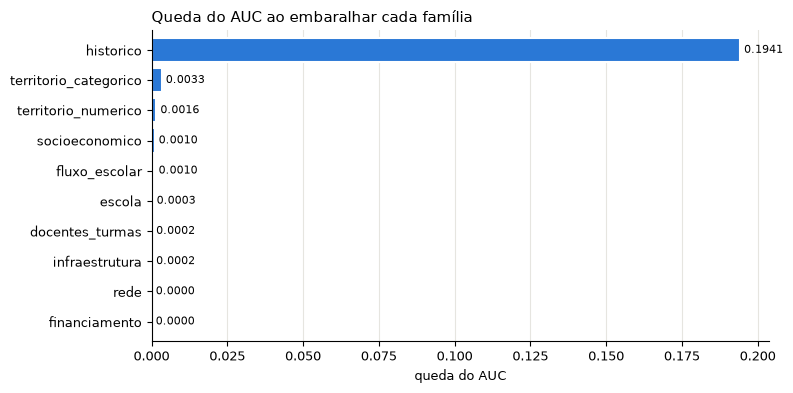

In [32]:
linhas = []
for familia, colunas in par_familias.items():
    quedas = []
    for _ in range(3):
        permutado = df_interpretacao.copy()
        permutado[colunas] = permutado[colunas].values[rng.permutation(len(permutado))]
        quedas.append(base_auc - roc_auc_score(df_interpretacao[par_alvo], prever(modelo_final, permutado), sample_weight=df_interpretacao[par_peso]))
    linhas.append({"familia": familia, "queda_auc": np.mean(quedas), "dp": np.std(quedas)})
df_importancia_familia = pd.DataFrame(linhas).sort_values("queda_auc", ascending=False)
plot_barras(df_importancia_familia, "familia", "queda_auc", titulo="Queda do AUC ao embaralhar cada família", xlabel="queda do AUC", fmt="%.4f")

#### SHAP

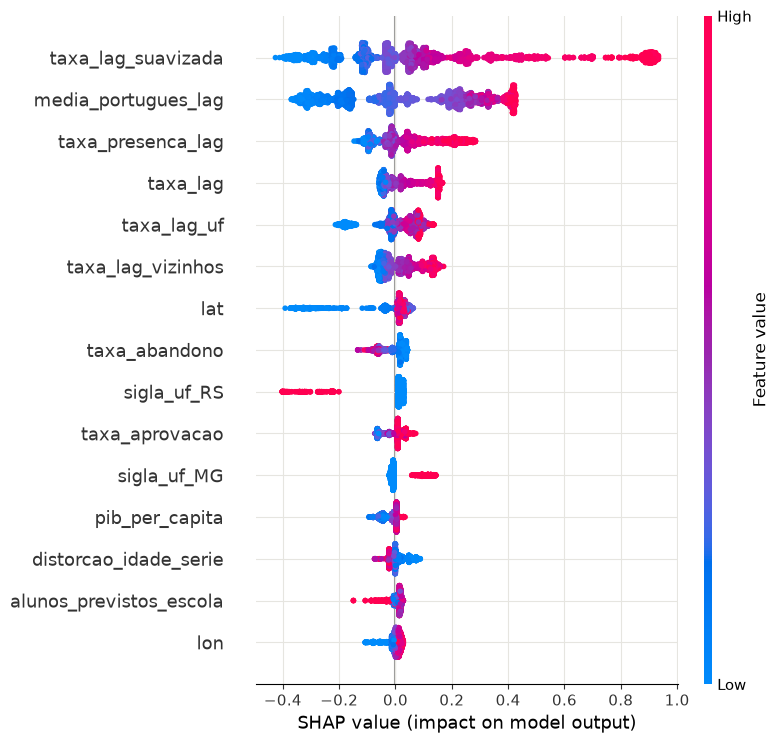

In [33]:
prep_final = modelo_final.named_steps["prep"]
estimador_final = modelo_final.named_steps["modelo"]
df_shap_base = df_teste.sample(par_amostra_interpretacao, random_state=par_seed)
X_shap = pd.DataFrame(prep_final.transform(df_shap_base[par_features]), columns=[c.split("__")[1].replace("missingindicator_", "ausente_") for c in prep_final.get_feature_names_out()]).astype(float)
if hasattr(estimador_final, "coef_"):
    valores_shap = shap.Explainer(estimador_final, shap.maskers.Independent(X_shap.sample(300, random_state=par_seed), max_samples=300))(X_shap)
else:
    valores_shap = shap.TreeExplainer(estimador_final)(X_shap)
valores = valores_shap.values[..., -1] if valores_shap.values.ndim == 3 else valores_shap.values
shap.summary_plot(valores, X_shap, max_display=15, show=False)
plt.tight_layout()
plt.show()

In [34]:
pd.Series(np.abs(valores).mean(axis=0), index=X_shap.columns, name="shap_medio_abs").sort_values(ascending=False).head(15).to_frame()

,shap_medio_abs
taxa_lag_suavizada,0.242
media_portugues_lag,0.225
taxa_presenca_lag,0.085
taxa_lag,0.062
taxa_lag_uf,0.060
taxa_lag_vizinhos,0.060
lat,0.051
taxa_abandono,0.032
sigla_uf_RS,0.031
taxa_aprovacao,0.027


**Decisão:** adotar o LightGBM para priorizar territórios e redes, e não para avaliar alunos individualmente, já que as features descrevem o contexto do aluno, e não o próprio aluno.

**Desempenho no teste**
- O AUC foi de 0,730 (IC 95% de 0,677 a 0,778 por bootstrap de mesorregiões), empatado com a Logística L2 (0,730). A regressão é uma alternativa mais simples com desempenho equivalente.
- O ganho é pequeno, mas o intervalo não inclui zero: 0,016 sobre a persistência (IC de 0,006 a 0,028) e 0,011 sobre o KNN (IC de 0,007 a 0,019).
- Conhecer a taxa real de 2024 levaria o AUC a 0,751 por município e rede e a 0,798 por escola. Parte do que falta depende de informação da escola e do próprio aluno.

**O AUC do teste precisa de cautela**
- Ele é maior que o da validação cruzada (0,634) e o da partição de validação (0,664) e depende da composição do teste, que reúne estados muito diferentes, como CE (89,6% de alfabetizados) e BA (30,8%).
- Boa parte do resultado vem de separar estados: o AUC vai de 0,538 a 0,757 dentro de cada UF, com 0,815 no Nordeste e de 0,538 a 0,640 nas demais regiões.
- Em estados nunca vistos, o AUC foi de 0,629. Esse valor é mais prudente como expectativa de generalização.

**Uso das probabilidades**
- A calibração é boa: as diferenças entre previsto e observado por decil ficam em até 0,044 ponto de proporção. O maior viés por UF ocorre em MS (+6,6 p.p.) e SC (-4,5 p.p.).
- O limiar de 0,63, definido na validação, sobe a acurácia balanceada de 0,640 para 0,669 e o F1 de não alfabetizados de 0,527 para 0,617, com queda do F1 de alfabetizados de 0,760 para 0,678. Ele é preferível quando o objetivo é encontrar quem precisa de apoio.
- Agregadas por município, as previsões atingem R² de 0,712 e RMSE de 11,23 p.p. em 1.135 municípios, o que sustenta o uso territorial.

**O que explica as previsões**
- O histórico domina: embaralhar essa família derruba o AUC em 0,194, e `taxa_lag_suavizada` e `media_portugues_lag` lideram na permutação e no SHAP.
- Removê-lo e treinar de novo custa só 0,032, porque as demais variáveis compensam parte da perda. Sem histórico, treinando em 2023, o AUC no teste de 2024 foi de 0,708.
- As demais famílias, isoladamente, pouco acrescentam: a remoção de cada uma custa no máximo 0,003. Como os resultados são associações, não indicam o efeito causal de intervir em uma variável.

### 15. Salvar artefatos

In [35]:
modelo_producao = ajustar(modelos[par_melhor], df_2024)
joblib.dump(modelo_producao, par_entrada / "modelo_aluno.joblib")
df_resultados.to_csv(par_entrada / "resultados_modelos_aluno.csv", index=False)
df_importancia.to_csv(par_entrada / "importancia_aluno.csv", index=False)
print("Modelo final:", par_melhor, "| Limiar:", round(par_limiar, 2), "| Alunos no ajuste:", len(df_2024))

Modelo final: LightGBM | Limiar: 0.63 | Alunos no ajuste: 1851828
